# Benchmark leakage (RQ1)

Label-based, no-gap and honest persistence at 1–14 days, the inflation and its split into the five-day minimum and gap joining, with year-block bootstrap CIs, for the Bay of Bengal, the Levantine Sea and the South China Sea.

**Thesis:** Sections 3.4, 3.11, 4.3.1 · Table 4.2 · Figs. 4.5, 4.6 · Appendix C.4  
**Input:** predictor_table_1982_2025.csv, OISST for the two comparison boxes  
**Output:** wp1_leakage_curve_*.csv, wp1_event_stats_*.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

WP1-1 — Hobday detection and check against your labels

In [6]:
from google.colab import drive; drive.mount('/content/drive')
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
FIG  = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)
df = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)

def doy366(idx):
    d = idx.dayofyear.values.copy()
    d[(~idx.is_leap_year) & (idx.month > 2)] += 1          # 1 Mar is always day 61
    return d

def hobday_clim(s, base=(1982, 2021), win=5, smooth=31, pct=90):
    """Hobday et al. (2016) climatological mean and percentile threshold (as in Oliver's marineHeatWaves)."""
    v, d = s.values, doy366(s.index)
    inb = (s.index.year >= base[0]) & (s.index.year <= base[1])
    m, p = np.full(367, np.nan), np.full(367, np.nan)
    for k in range(1, 367):
        if k == 60: continue
        idx = np.where((d == k) & inb)[0]
        pool = np.unique(np.clip((idx[:, None] + np.arange(-win, win + 1)).ravel(), 0, len(v) - 1))
        x = v[pool[inb[pool]]]
        m[k], p[k] = np.nanmean(x), np.nanpercentile(x, pct)
    out = []
    for c in (m, p):
        c[60] = (c[59] + c[61]) / 2
        c = c[1:]
        c = np.convolve(np.r_[c[-(smooth // 2):], c, c[:smooth // 2]], np.ones(smooth) / smooth, 'valid')
        out.append(pd.Series(c[d - 1], index=s.index))
    return out                                               # clim_mean, threshold

def runs(b):
    """Start/end indices of consecutive True runs."""
    b = np.asarray(b, bool).astype(int)
    st = np.where(np.diff(np.r_[0, b]) == 1)[0]; en = np.where(np.diff(np.r_[b, 0]) == -1)[0]
    return st, en

def detect(sst, thr, min_dur=5, max_gap=2):
    """causal - knowable on day t: SST above threshold for >= min_dur consecutive days up to t
       nojoin - Hobday label with the minimum-duration rule only
       label  - full Hobday label: qualifying runs, then gaps <= max_gap days joined"""
    exc = (sst > thr).values
    n = len(exc)
    nojoin = np.zeros(n, int); causal = np.zeros(n, int)
    st, en = runs(exc)
    keep = [(s, e) for s, e in zip(st, en) if e - s + 1 >= min_dur]
    for s, e in keep:
        nojoin[s:e + 1] = 1
        causal[s + min_dur - 1:e + 1] = 1
    label = nojoin.copy()
    for (s1, e1), (s2, e2) in zip(keep[:-1], keep[1:]):
        if s2 - e1 - 1 <= max_gap: label[e1 + 1:s2] = 1
    f = lambda a: pd.Series(a, index=sst.index)
    return f(causal), f(nojoin), f(label)

# verification: rebuild your labels from SST alone (must match mhw_daily_labels.csv)
CHK = {}
for kind, s_col, t_col, l_col in (('raw', 'sst', 'thresh90', 'mhw_raw'),
                                  ('det', 'sst_detrended', 'thresh90_detrended', 'mhw_detrended')):
    clim, thr = hobday_clim(df[s_col])
    c, nj, lab = detect(df[s_col], thr)
    CHK[kind] = dict(thr_diff=float((thr - df[t_col]).abs().max()), days=int(lab.sum()),
                     days_file=int(df[l_col].sum()), mismatched_days=int((lab != df[l_col]).sum()))
print(pd.DataFrame(CHK).T)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
     thr_diff    days  days_file  mismatched_days
raw  0.000107  1652.0     1652.0              0.0
det  0.000274  1192.0     1192.0              0.0


WP1-2 — Leakage curve

In [7]:
LEADS = [1, 2, 3, 5, 7, 10, 14]
B = 2000

def mcc_from(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

def year_counts(pred, truth, years, yrs):
    g = pd.DataFrame({'tp': (pred == 1) & (truth == 1), 'fp': (pred == 1) & (truth == 0),
                      'fn': (pred == 0) & (truth == 1), 'tn': (pred == 0) & (truth == 0), 'year': years}).groupby('year').sum()
    return g.reindex(yrs, fill_value=0).values

def leakage_curve(sst, thr, region, kind):
    """Persistence forecasts for day t+h issued on day t, scored against the official Hobday label on t+h."""
    causal, nojoin, label = detect(sst, thr)
    yrs = sorted(sst.index.year.unique())
    idx = np.random.default_rng(0).integers(0, len(yrs), (B, len(yrs)))
    rows = []
    for h in LEADS:
        y = label.shift(-h).dropna().astype(int)
        years = y.index.year
        r = {'region': region, 'target': kind, 'lead': h}
        boot = {}
        for nm, s in (('label', label), ('nojoin', nojoin), ('causal', causal)):
            p = s.reindex(y.index).values
            c = year_counts(p, y.values, years, yrs)
            r[f'MCC_{nm}'] = float(mcc_from(*c.sum(0)))
            boot[nm] = mcc_from(*c[idx].sum(1).T)
        for a, b, nm in (('label', 'causal', 'inflation_total'), ('nojoin', 'causal', 'from_min_duration'),
                         ('label', 'nojoin', 'from_gap_joining')):
            d = boot[a] - boot[b]
            r[nm] = r[f'MCC_{a}'] - r[f'MCC_{b}']
            r[f'{nm}_lo'], r[f'{nm}_hi'] = np.percentile(d, 2.5), np.percentile(d, 97.5)
        r['inflation_pct'] = 100 * r['inflation_total'] / r['MCC_causal'] if r['MCC_causal'] > 0 else np.nan
        rows.append(r)
    # event statistics that explain the size of the leakage
    st, en = runs(label.values.astype(bool))
    dur = en - st + 1
    stj, enj = runs(nojoin.values.astype(bool))
    stats = {'region': region, 'target': kind, 'events': len(st), 'MHW_days': int(label.sum()),
             'median_duration': float(np.median(dur)), 'pct_events_<=10d': 100 * np.mean(dur <= 10),
             'pct_events_joined_across_gap': 100 * (1 - len(st) / max(len(stj), 1)) if len(stj) else np.nan,
             'pct_MHW_days_known_only_in_hindsight': 100 * float(((label == 1) & (causal == 0)).sum() / label.sum())}
    return pd.DataFrame(rows), stats

curves, stats = [], []
for kind, s_col in (('det', 'sst_detrended'), ('raw', 'sst')):
    _, thr = hobday_clim(df[s_col])
    c, s = leakage_curve(df[s_col], thr, 'Bay of Bengal', kind)
    curves.append(c); stats.append(s)
CUR = pd.concat(curves); STA = pd.DataFrame(stats)
CUR.to_csv(f'{PROC}/wp1_leakage_curve_bob.csv', index=False); STA.to_csv(f'{PROC}/wp1_event_stats_bob.csv', index=False)
pd.set_option('display.width', 220)
show = ['target', 'lead', 'MCC_label', 'MCC_nojoin', 'MCC_causal', 'inflation_total', 'inflation_total_lo',
        'inflation_total_hi', 'inflation_pct', 'from_min_duration', 'from_gap_joining']
print(CUR[show].round(3).to_string(index=False))
print(); print(STA.round(1).to_string(index=False))

target  lead  MCC_label  MCC_nojoin  MCC_causal  inflation_total  inflation_total_lo  inflation_total_hi  inflation_pct  from_min_duration  from_gap_joining
   det     1      0.901       0.893       0.625            0.277               0.247               0.317         44.302              0.269             0.008
   det     2      0.802       0.794       0.517            0.285               0.254               0.330         55.149              0.277             0.009
   det     3      0.704       0.695       0.438            0.266               0.237               0.305         60.699              0.257             0.009
   det     5      0.510       0.499       0.324            0.186               0.161               0.217         57.548              0.176             0.010
   det     7      0.377       0.369       0.265            0.111               0.082               0.143         41.974              0.104             0.008
   det    10      0.272       0.268       0.207           

WP1-3 — Headline figure

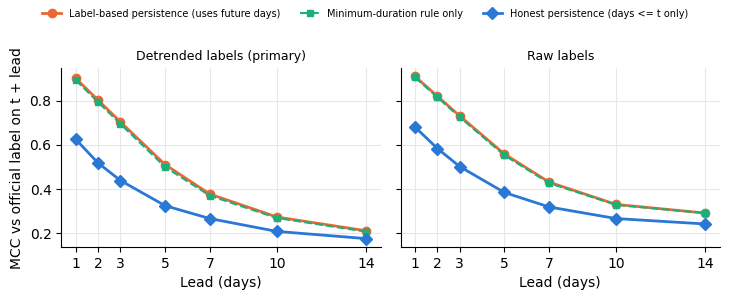

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), sharey=True)
for ax, kind, ttl in zip(axs, ('det', 'raw'), ('Detrended labels (primary)', 'Raw labels')):
    c = CUR[CUR.target == kind]
    ax.plot(c.lead, c.MCC_label, 'o-', color='#eb6834', lw=2, ms=6, label='Label-based persistence (uses future days)')
    ax.plot(c.lead, c.MCC_nojoin, 's--', color='#1baf7a', lw=1.5, ms=5, label='Minimum-duration rule only')
    ax.plot(c.lead, c.MCC_causal, 'D-', color='#2a78d6', lw=2, ms=6, label='Honest persistence (days <= t only)')
    ax.set_title(ttl, fontsize=9); ax.set_xlabel('Lead (days)'); ax.set_xticks(LEADS)
    ax.grid(color='#e4e7eb', lw=0.8); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
axs[0].set_ylabel('MCC vs official label on t + lead')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=3, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f'{FIG}/wp1_leakage_curve_bob.png', dpi=300)

WP1b-1 — Download and extract both boxes

In [9]:
import subprocess, xarray as xr
BOXES = {'levantine': dict(lat=(32.0, 35.5), lon=(26.0, 32.0)),     # eastern Mediterranean
         'scs':       dict(lat=(10.0, 18.0), lon=(111.0, 119.0))}   # central South China Sea
OUTD = f'{PROC}/wp1b'; os.makedirs(OUTD, exist_ok=True)
TMP  = '/content/oisst_tmp'; os.makedirs(TMP, exist_ok=True)
DL   = 'https://downloads.psl.noaa.gov/Datasets/noaa.oisst.v2.highres/sst.day.mean.{}.nc'

def box_mean(sst, b):
    x = sst.sel(lat=slice(*b['lat']), lon=slice(*b['lon']))
    ocean = x.notnull().all('time')                                  # cells that are ocean all year
    w = np.cos(np.deg2rad(x.lat)) * ocean
    return (x * w).sum(('lat', 'lon')) / w.sum(), int(ocean.sum())

for yr in range(1982, 2026):
    outs = {k: f'{OUTD}/{k}_{yr}.csv' for k in BOXES}
    if all(os.path.exists(f) for f in outs.values()): continue
    f = f'{TMP}/sst_{yr}.nc'
    r = subprocess.run(['wget', '-q', '-c', '--tries=10', '--waitretry=60', '-O', f, DL.format(yr)])
    if r.returncode != 0: raise RuntimeError(f'{yr}: download failed, wget code {r.returncode}')
    with xr.open_dataset(f) as ds:
        sst = ds.sst.load()
    msg = [str(yr)]
    for k, b in BOXES.items():
        m, n = box_mean(sst, b)
        pd.DataFrame({'sst': m.values, 'ocean_cells': n}, index=pd.to_datetime(sst.time.values)).to_csv(outs[k])
        msg.append(f'{k}: {n} cells')
    os.remove(f); print(' | '.join(msg))

WP1b-2 — Leakage curves in all three regions


===== det: MCC inflation (label-based minus honest persistence), 95% CI =====
region  Bay of Bengal  Levantine Sea  South China Sea
lead                                                 
1               0.277          0.255            0.194
2               0.285          0.249            0.197
3               0.266          0.231            0.187
5               0.186          0.164            0.140
7               0.111          0.141            0.102
10              0.065          0.115            0.091
14              0.036          0.061            0.064
region   Bay of Bengal   Levantine Sea South China Sea
lead                                                  
1       0.247 to 0.317  0.215 to 0.301  0.158 to 0.245
2        0.254 to 0.33  0.206 to 0.296  0.159 to 0.251
3       0.237 to 0.305  0.185 to 0.278   0.149 to 0.24
5       0.161 to 0.217  0.115 to 0.207  0.108 to 0.183
7       0.082 to 0.143  0.092 to 0.182  0.074 to 0.138
10      0.034 to 0.096   0.07 to 0.162  0.059 to 0

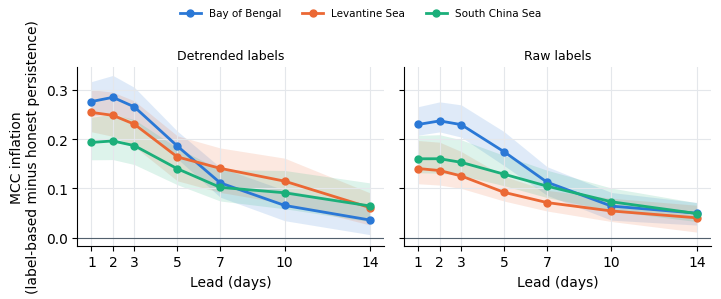

In [10]:
import glob
OUTD = f'{PROC}/wp1b'
REG = {'Bay of Bengal': df.sst}
for k, name in (('levantine', 'Levantine Sea'), ('scs', 'South China Sea')):
    s = pd.concat([pd.read_csv(f, index_col=0, parse_dates=True) for f in sorted(glob.glob(f'{OUTD}/{k}_*.csv'))])
    assert len(s) == len(df) and s.ocean_cells.nunique() == 1, f'{k}: missing days or changing ocean mask'
    REG[name] = s.sst

def detrend(s):
    t = np.arange(len(s)); p = np.polyfit(t, s.values, 1)
    return s - p[0] * (t - t.mean()), p[0] * 3652.5                  # detrended series, trend per decade

curves, stats = [], []
for name, sst in REG.items():
    sdet, trend = detrend(sst)
    for kind, s in (('det', sdet), ('raw', sst)):
        _, thr = hobday_clim(s)
        c, st = leakage_curve(s, thr, name, kind)
        st['trend_C_per_decade'] = trend
        curves.append(c); stats.append(st)
CUR3 = pd.concat(curves); STA3 = pd.DataFrame(stats)
CUR3.to_csv(f'{PROC}/wp1_leakage_curve_3regions.csv', index=False); STA3.to_csv(f'{PROC}/wp1_event_stats_3regions.csv', index=False)

# effective lead lost: label-based persistence at lead h equals honest persistence at which shorter lead?
def lead_lost(c):
    h, lab, cau = c.lead.values, c.MCC_label.values, c.MCC_causal.values
    eq = np.interp(lab, cau[::-1], h[::-1])                          # honest-persistence lead with the same MCC
    eq = np.where(lab > cau.max(), np.nan, eq)                       # would need a lead shorter than 1 day
    return pd.Series(h - eq, index=h).round(1)

for kind in ('det', 'raw'):
    print(f'\n===== {kind}: MCC inflation (label-based minus honest persistence), 95% CI =====')
    t = CUR3[CUR3.target == kind].assign(CI=lambda x: x.inflation_total_lo.round(3).astype(str) + ' to ' + x.inflation_total_hi.round(3).astype(str))
    print(t.pivot(index='lead', columns='region', values='inflation_total').round(3).to_string())
    print(t.pivot(index='lead', columns='region', values='CI').to_string())
    print('-- days of lead effectively lost by label-based persistence --')
    print(pd.DataFrame({r: lead_lost(g) for r, g in t.groupby('region')}).to_string())
print(); print(STA3.round(2).to_string(index=False))

cols = {'Bay of Bengal': '#2a78d6', 'Levantine Sea': '#eb6834', 'South China Sea': '#1baf7a'}
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), sharey=True)
for ax, kind, ttl in zip(axs, ('det', 'raw'), ('Detrended labels', 'Raw labels')):
    for name, g in CUR3[CUR3.target == kind].groupby('region'):
        ax.fill_between(g.lead, g.inflation_total_lo, g.inflation_total_hi, color=cols[name], alpha=0.15, lw=0)
        ax.plot(g.lead, g.inflation_total, 'o-', color=cols[name], lw=2, ms=5, label=name)
    ax.axhline(0, color='#52606d', lw=0.8); ax.set_xticks(LEADS); ax.set_xlabel('Lead (days)'); ax.set_title(ttl, fontsize=9)
    ax.grid(color='#e4e7eb', lw=0.8); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
axs[0].set_ylabel('MCC inflation\n(label-based minus honest persistence)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=3, fontsize=7.5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f'{FIG}/wp1_leakage_3regions.png', dpi=300)